# Manufacturing Quality Control Analysis: SECOM Semiconductor Line
**Author:** David Ayaya
**Tools:** Python, Pandas, NumPy, Matplotlib
**Data:** [UCI SECOM dataset](https://archive.ics.uci.edu/dataset/179/secom) (CC BY 4.0): 1,567 production runs from a real semiconductor manufacturing line (Jul to Oct 2008), 590 sensor readings per run, and a pass/fail result from in-line testing.

**Questions**
1. What is the line's yield, and is the failure rate stable over time?
2. Which sensor signals are most associated with failures?
3. Would a statistical process control (SPC) chart on that signal have caught the problem?
4. How clean is the sensor data, and what should a monitoring plan include?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

X = pd.read_csv("data/secom.data.txt", sep=r"\s+", header=None, na_values="NaN")
X.columns = [f"S{i+1:03d}" for i in range(X.shape[1])]
lab = pd.read_csv("data/secom_labels.data.txt", sep=" ", header=None, names=["result", "ts"])
lab["ts"] = pd.to_datetime(lab["ts"].str.strip('"'), format="%d/%m/%Y %H:%M:%S")
lab["fail"] = (lab["result"] == 1).astype(int)          # 1 = failed test, -1 = passed
df = pd.concat([lab, X], axis=1).sort_values("ts").reset_index(drop=True).copy()

p_bar = df["fail"].mean()
print(f"Runs: {len(df):,}   Sensors: {X.shape[1]}   Failures: {df.fail.sum()}")
print(f"Yield: {(1 - p_bar):.2%}   Failure rate: {p_bar:.2%}")
print(f"Period: {df.ts.min():%b %d, %Y} to {df.ts.max():%b %d, %Y}")

Runs: 1,567   Sensors: 590   Failures: 104
Yield: 93.36%   Failure rate: 6.64%
Period: Jul 19, 2008 to Oct 17, 2008


## 1. Data quality check
Before trusting any chart, I check for missing values and sensors that never change (they carry no information).

In [2]:
miss = X.isna().mean()
const = X.nunique(dropna=True) <= 1
print(f"Missing cells overall: {X.isna().values.mean():.1%}")
print(f"Constant sensors (no variation): {const.sum()}")
print(f"Sensors more than 50% missing: {(miss > 0.5).sum()}")
print(f"Usable sensors: {((miss <= 0.5) & ~const).sum()} of {X.shape[1]}")

Missing cells overall: 4.5%
Constant sensors (no variation): 116
Sensors more than 50% missing: 28
Usable sensors: 446 of 590


## 2. Is the failure rate stable? Weekly p-chart
A p-chart plots the share of failed runs each week against 3-sigma control limits based on the overall failure rate. Limits are wider in weeks with fewer runs.

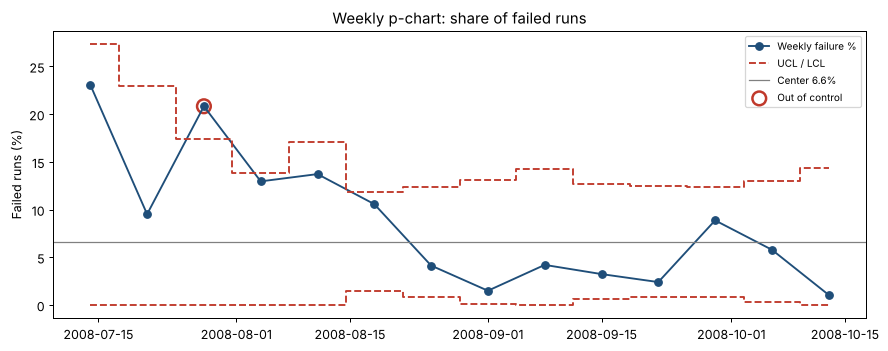

Jul 19 to Aug 24: 449 runs, failure rate 12.9%
Aug 25 to Oct 17: 1,118 runs, failure rate 4.1%


In [3]:
df["week"] = df["ts"].dt.to_period("W-SUN").dt.start_time
wk = df.groupby("week").agg(n=("fail", "size"), fails=("fail", "sum")).reset_index()
wk["p"] = wk.fails / wk.n
wk["ucl"] = (p_bar + 3 * np.sqrt(p_bar * (1 - p_bar) / wk.n)).clip(upper=1)
wk["lcl"] = (p_bar - 3 * np.sqrt(p_bar * (1 - p_bar) / wk.n)).clip(lower=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wk.week, wk.p * 100, marker="o", color="#1f4e79", label="Weekly failure %")
ax.step(wk.week, wk.ucl * 100, where="mid", ls="--", color="#c0392b", label="UCL / LCL")
ax.step(wk.week, wk.lcl * 100, where="mid", ls="--", color="#c0392b")
ax.axhline(p_bar * 100, color="gray", lw=1, label=f"Center {p_bar:.1%}")
ooc = wk[(wk.p > wk.ucl) | (wk.p < wk.lcl)]
ax.scatter(ooc.week, ooc.p * 100, s=120, facecolors="none", edgecolors="#c0392b", lw=2, label="Out of control")
ax.set_ylabel("Failed runs (%)"); ax.set_title("Weekly p-chart: share of failed runs"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

CUT = pd.Timestamp("2008-08-25")
for name, part in [("Jul 19 to Aug 24", df[df.ts < CUT]), ("Aug 25 to Oct 17", df[df.ts >= CUT])]:
    print(f"{name}: {len(part):,} runs, failure rate {part.fail.mean():.1%}")

**Finding:** the line was not stable. The week of Jul 28 broke the upper control limit, and the failure rate fell sharply from about **12.9%** to about **4.1%** starting the week of Aug 25. Something in the process changed. The next step is to find which signal moved at the same time.

## 3. Which sensors are most associated with failures?
For every sensor with at most 5% missing data, I compare failed and passed runs using a standardized mean difference (Cohen's d). A larger |d| means the sensor looks more different on failed runs. This shows association, not cause.

In [4]:
usable = [c for c in X.columns if miss[c] <= 0.05 and not const[c]]
rows = []
for c in usable:
    a, b = df.loc[df.fail == 1, c].dropna(), df.loc[df.fail == 0, c].dropna()
    sd = np.sqrt((a.var() + b.var()) / 2)
    if sd > 0:
        rows.append((c, (a.mean() - b.mean()) / sd, a.mean(), b.mean()))
eff = pd.DataFrame(rows, columns=["sensor", "d", "mean_fail", "mean_pass"])
top = eff.reindex(eff.d.abs().sort_values(ascending=False).index).head(8)
print(top.round(3).to_string(index=False))

sensor      d  mean_fail  mean_pass
  S060  0.590      8.515      2.563
  S104  0.571     -0.008     -0.010
  S130  0.478     -0.083     -0.588
  S029 -0.444     68.101     69.598
  S511  0.427     74.348     54.441
  S317 -0.384      5.636      6.001
  S125  0.377     15.835     15.792
  S126 -0.369      1.097      1.191


## 4. SPC check on sensor S060: individuals (I-MR) control chart
S060 is the strongest signal. I set control limits from the **stable period** (Aug 25 onward) using the average moving range (sigma = MR-bar / 1.128), then plot every run against those limits.

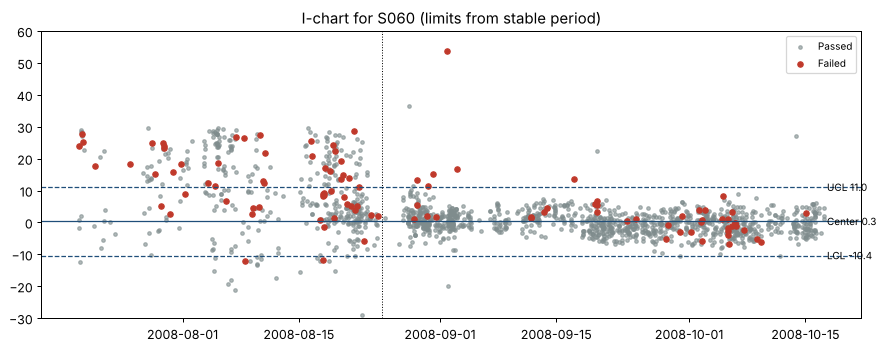

                  runs  failure_rate  outside_limits  median_S060
period                                                           
Aug 25 to Oct 17  1111         0.041           0.013       -0.018
Jul 19 to Aug 24   449         0.129           0.474        8.095

Runs outside limits failed 17.6% of the time vs 4.8% inside limits.


In [5]:
key = "S060"
s = df[["ts", "fail", key]].dropna().reset_index(drop=True)
base = s[s.ts >= CUT]
center = base[key].mean()
sigma = base[key].diff().abs().mean() / 1.128
ucl, lcl = center + 3 * sigma, center - 3 * sigma
s["ooc"] = (s[key] > ucl) | (s[key] < lcl)

fig, ax = plt.subplots(figsize=(10, 4))
ok, bad = s[s.fail == 0], s[s.fail == 1]
ax.scatter(ok.ts, ok[key], s=8, color="#7f8c8d", alpha=.6, label="Passed")
ax.scatter(bad.ts, bad[key], s=18, color="#c0392b", label="Failed")
for y, lbl in [(ucl, "UCL"), (center, "Center"), (lcl, "LCL")]:
    ax.axhline(y, ls="--" if lbl != "Center" else "-", color="#1f4e79", lw=1)
    ax.text(s.ts.max(), y, f" {lbl} {y:.1f}", va="center", fontsize=8)
ax.axvline(CUT, color="black", lw=.8, ls=":")
ax.set_ylim(-30, 60); ax.set_title(f"I-chart for {key} (limits from stable period)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

s["period"] = np.where(s.ts < CUT, "Jul 19 to Aug 24", "Aug 25 to Oct 17")
summary = s.groupby("period").agg(runs=("fail", "size"), failure_rate=("fail", "mean"),
                                  outside_limits=("ooc", "mean"), median_S060=(key, "median"))
print(summary.round(3))
print(f"\nRuns outside limits failed {s[s.ooc].fail.mean():.1%} of the time vs {s[~s.ooc].fail.mean():.1%} inside limits.")

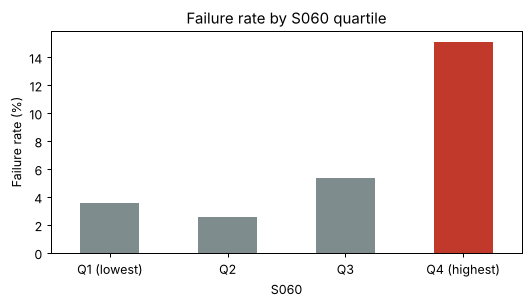

              failure_rate  runs
S060                            
Q1 (lowest)            3.6   390
Q2                     2.6   390
Q3                     5.4   390
Q4 (highest)          15.1   390


In [6]:
q = pd.qcut(s[key], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
by_q = s.groupby(q, observed=True).fail.agg(failure_rate="mean", runs="size")
ax = (by_q.failure_rate * 100).plot.bar(color=["#7f8c8d"] * 3 + ["#c0392b"], figsize=(6, 3.5), rot=0)
ax.set_ylabel("Failure rate (%)"); ax.set_title("Failure rate by S060 quartile")
plt.tight_layout(); plt.show()
print(by_q.assign(failure_rate=lambda d: (d.failure_rate * 100).round(1)))

## 5. Conclusions and recommendations
1. **Yield was 93.4% overall, but the process was not stable.** The failure rate dropped from about 12.9% (Jul 19 to Aug 24) to about 4.1% (Aug 25 onward), a reduction of roughly two-thirds.
2. **Sensor S060 tracks the improvement.** Its median moved from about 8 to about 0, and nearly half of the early runs fall outside the control limits of the stable period, versus about 1% afterward.
3. **S060 is a useful early warning.** Runs outside its control limits failed about 17.6% of the time, versus 4.8% inside. Runs in its highest quartile failed 15.1%, versus 2.6% to 5.4% for the other quartiles.
4. **Recommended monitoring plan**
   - Put S060 on a live I-MR chart with the stable-period limits and alert on any point outside them.
   - Document what changed around Aug 25 (maintenance, recipe, material lot) in the change-control record, so the improvement can be held.
   - Remove the 116 constant sensors and the 28 sensors that are mostly missing from dashboards, so operators focus on signals that matter.

*Caveat:* this is observational data with anonymized sensors, so these results show association, not proven cause. In a real plant, the next step would be a root-cause investigation with process engineering before changing any limits.